### **Estudo de Reconstrução 3D.**
Este notebook tem por objetivo estudar e registrar ferramentas e fórmulas teóricas para cálculo da profundidade estimada de cada pixel para reconstrução 3d.

In [229]:
# Bibliotecas.
from utils.alignment import load_images
from scipy.ndimage import convolve
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import cv2 as cv
import gco

In [230]:
# Função de Apoio - Visualização;
def show(array):
    pos_color = np.array([0.36, 0.82, 0.8])
    neg_color = np.array([0.99, 0.18, 0.13])
    array = np.array(array)
    pos = np.maximum(array, 0)[..., np.newaxis]
    neg = np.maximum(-array, 0)[..., np.newaxis]
    colored = pos * pos_color + neg * neg_color
    normalized = colored / np.max(np.abs(array))
    
    img = Image.fromarray((normalized * 255).astype(np.uint8))
    return(img)

In [231]:
# Imagens Alinhadas.
images = load_images("../src/images/boxes")
ref = cv.cvtColor(images[0], cv.COLOR_BGR2GRAY)


Fase 1.1: Ordenação.
Ordem de carregamento detectada: ['01.png', '02.png', '03.png'] ...


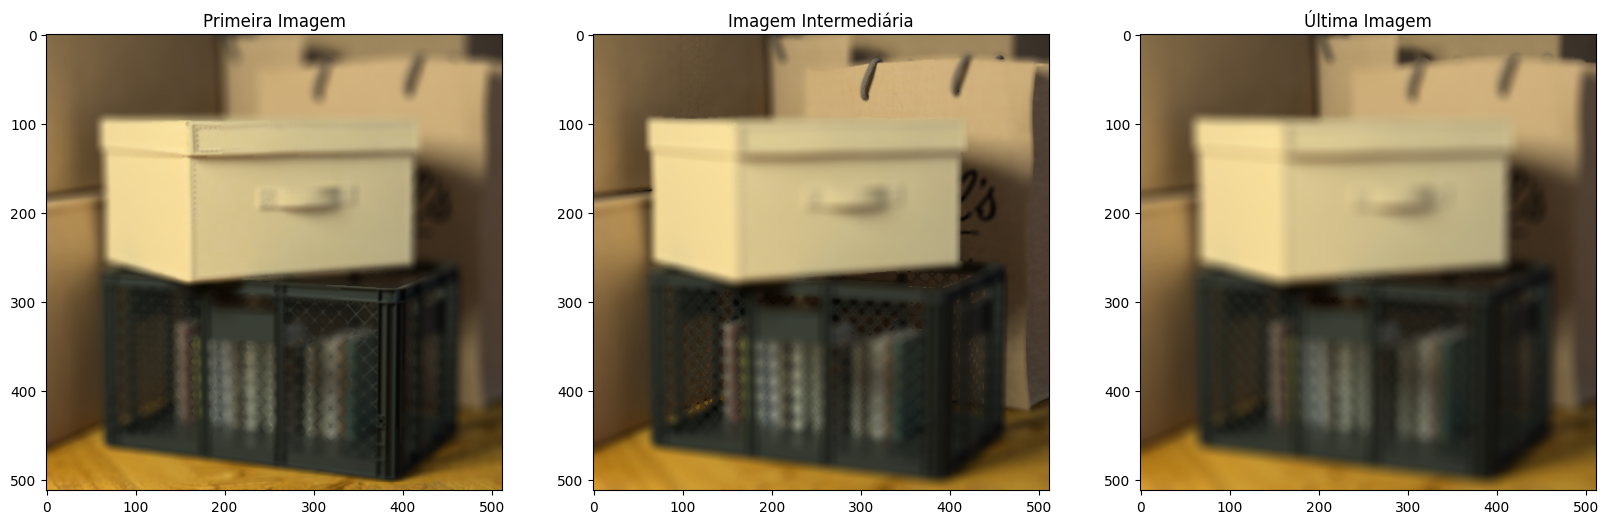

In [232]:
# Visualização das Imagens.
n = len(images)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 10))
ax1.imshow(cv.cvtColor(images[0], cv.COLOR_BGR2RGB), cmap='jet')
ax2.imshow(cv.cvtColor(images[n//2], cv.COLOR_BGR2RGB), cmap='jet')
ax3.imshow(cv.cvtColor(images[-1], cv.COLOR_BGR2RGB), cmap='jet')

ax1.set_title("Primeira Imagem")
ax2.set_title("Imagem Intermediária")
ax3.set_title("Última Imagem")

plt.show()

Uma vez que as imagens estão alinhadas, podemos avaliar as derivadas das imagens, utilizando o filtro de Sobel.

In [233]:
# Função de Apoio - Filtro de Sobel.
def edgeness(img):
    Sx = np.array([[-1, 0, 1],
                   [-2, 0, 2],
                   [-1, 0, 1]]) / 8
    Sy = Sx.T

    if img.ndim == 3:
        b = cv.cvtColor(img, cv.COLOR_BGR2GRAY) / 255.0
    else:
        b = img / 255.0

    grad_x = convolve(b, Sx)
    grad_y = convolve(b, Sy)

    return np.sqrt(grad_x**2 + grad_y**2)

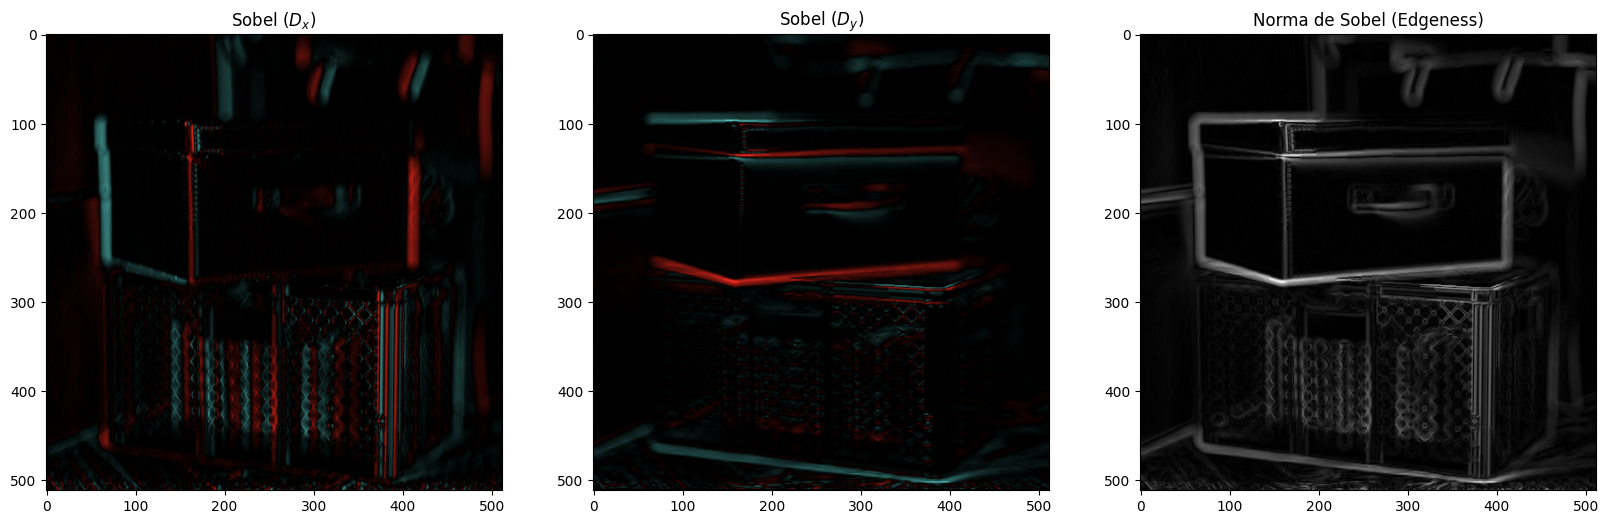

In [234]:
# Visualização Gráfica do Filtro de Sobel e Edgeness.

dx = cv.Sobel(src=ref, ddepth=cv.CV_64F, dx=1, dy=0)
dy = cv.Sobel(src=ref, ddepth=cv.CV_64F, dx=0, dy=1)

# Visualização das Imagens.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 10))
ax1.imshow(show(dx))
ax2.imshow(show(dy))
ax3.imshow(edgeness(ref), cmap='gray')

ax1.set_title("Sobel ($D_{x}$)")
ax2.set_title("Sobel ($D_{y}$)")
ax3.set_title("Norma de Sobel (Edgeness)")

plt.show()

Agora, vamos avaliar o laplaciano das imagens de referência $i_{0}$ e $i_{20}$, a fim de detectar os pontos de foco. 

**Obs:** Como nas camadas de foco, a frequência de nitidez gerada pelo Laplaciano é alta, observamos os resultados de duas maneiras: **com e sem filtro passa-baixa.**

In [235]:
# Função de Apoio - Laplaciano
def laplacian(img):
    L = np.array([[1,  1, 1],
                  [1, -8, 1],
                  [1,  1, 1]])

    if img.ndim == 3:
        b = cv.cvtColor(img, cv.COLOR_BGR2GRAY) / 255.0
    else:
        b = img / 255.0

    return convolve(b, L)

In [236]:
# Função de Apoio - Blur Gaussiano
def gaussian_blur(img):
    gauss = cv.GaussianBlur(img, (5, 5), 0)
    return gauss

In [237]:
# Função de Apoio - Maginitude de Nitidez
def focus(img, blur = 0):
    
    L = laplacian(img) 

    if blur:
        L = gaussian_blur(L)

    magnitude = np.absolute(L)

    return np.uint8(magnitude * 255)

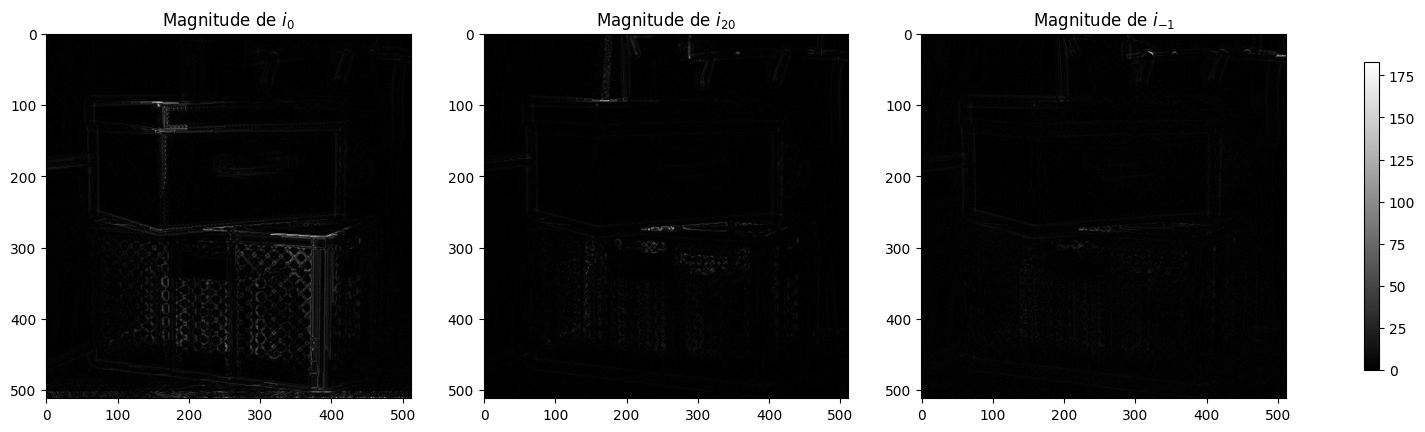

In [238]:
# Visualização das Imagens - Sem Filtro.
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
im = axs[0].imshow(focus(ref), cmap="gray")
axs[1].imshow(focus(images[20]), cmap="gray")
axs[2].imshow(focus(images[-1]), cmap="gray")

axs[0].set_title("Magnitude de $i_{0}$")
axs[1].set_title("Magnitude de $i_{20}$")
axs[2].set_title("Magnitude de $i_{-1}$")

fig.colorbar(im, ax=axs.tolist(), shrink=0.8)

plt.show()

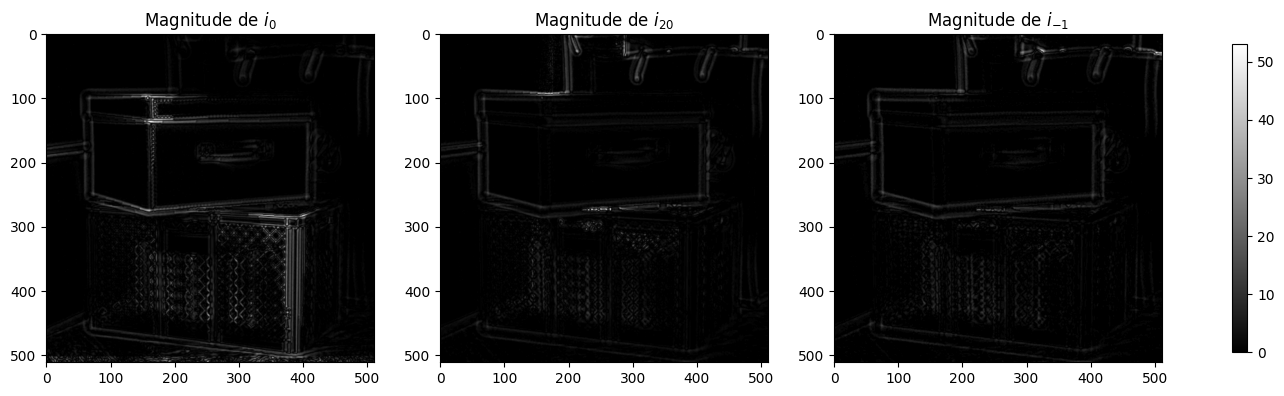

In [239]:
# Visualização das Imagens - Com Filtro.
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
im = axs[0].imshow(focus(ref, 1), cmap="gray")
axs[1].imshow(focus(images[20], 1), cmap="gray")
axs[2].imshow(focus(images[-1], 1), cmap="gray")

axs[0].set_title("Magnitude de $i_{0}$")
axs[1].set_title("Magnitude de $i_{20}$")
axs[2].set_title("Magnitude de $i_{-1}$")

fig.colorbar(im, ax=axs.tolist(), shrink=0.8)

plt.show()

Com as funções auxiliares em mãos, podemos construir a função que vai estimar a profundidade de cada pixel, com base no Volume de Nitidez da pilha de imagens.

In [240]:
# Função de Apoio - Mapa de Profundidade
def depth(images):
    """
    Realiza o Depth from Focus (DfF) para gerar a imagem nítida e mapas de dados.
    
    Parâmetros:
      images: Lista de imagens (numpy arrays) alinhadas.

    Retorna:
      Um dicionário com:
      - 'image': Imagem final.
      - 'depth_map': Mapa de índices.
      - 'confidence_map': Mapa de nitidez.
      - 'volume': Cubo de nitidez.
    """

    h, w = images[0].shape[:2]
    n = len(images)
    
    # 1. Alocação de Memória (Cubo de Nitidez)
    sharpness_cube = np.zeros((h, w, n), dtype=np.float32)
    
    # 2. Loop de Cálculo de Nitidez    
    for i, img in enumerate(images):
    
        ref = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
        L = focus(ref, blur=0)
        
        sharpness_cube[:, :, i] = L

    # 3. Seleção de Camada
    depth_index = np.argmax(sharpness_cube, axis=2)   # Mapa de Profundidade Bruto (Índices)
    confidence_map = np.max(sharpness_cube, axis=2)   # Mapa de Confiança (Valor da Magnitude)

    # 4. Reconstrução da Imagem  
    all_in_focus = np.zeros_like(images[0])    
    rows, cols = np.indices((h, w))
    
    stack_imgs = np.stack(images, axis=-1)     
    for c in range(3): 
        all_in_focus[:, :, c] = stack_imgs[:, :, c, :][rows, cols, depth_index]
    

    return {
        'image': all_in_focus,
        'depth_map': depth_index,
        'confidence': confidence_map,
        'volume': sharpness_cube
    }

In [241]:
results = depth(images)

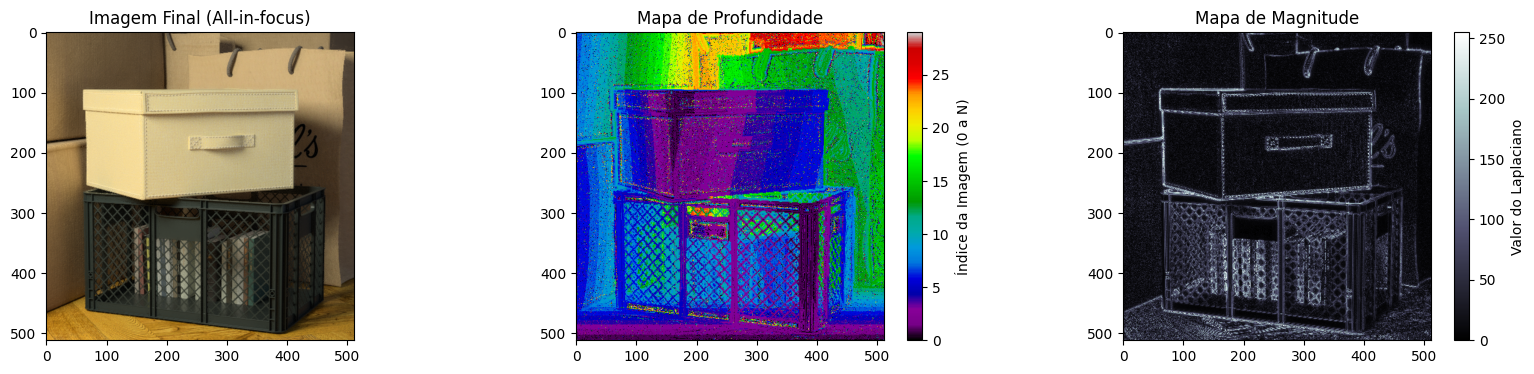

In [242]:
# Mapas de Profundidade

img = results['image']
depth = results['depth_map']
mag = results['confidence']

# Visualização das Imagens.
fig, axs = plt.subplots(1, 3, figsize=(20, 4))

axs[0].imshow(cv.cvtColor(results['image'], cv.COLOR_BGR2RGB), cmap='jet')

im1 = axs[1].imshow(depth, cmap='nipy_spectral')
fig.colorbar(im1, ax=axs[1], label='Índice da Imagem (0 a N)')

im2 = axs[2].imshow(mag, cmap='bone')
plt.colorbar(im2, ax=axs[2], label='Valor do Laplaciano')

axs[0].set_title("Imagem Final (All-in-focus)")
axs[1].set_title("Mapa de Profundidade")
axs[2].set_title("Mapa de Magnitude")

plt.show()

### **Graph Cut**

A abordagem de Graph Cut está intimamente relacionada a teoria de Markov Random Fields (MRF) e Energia.

Se calcularmos o foco puramente pixel a pixel, um pequeno ruído na textura do fóssil fará com que o algoritmo "pense" que aquele pixel específico está em uma profundidade completamente diferente do restante da superfície. Para resolver isso, modelamos o problema usando um Markov Random Field (MRF).

A hipótese do MRF é: no mundo físico, superfícies tendem a ser contínuas. Logo, pixels vizinhos têm uma alta probabilidade de pertencerem à mesma profundidade, a menos que haja uma descontinuidade real (uma borda do objeto).

Transformamos essa premissa em um problema de Minimização de Energia. Queremos encontrar a configuração de profundidades para todos os pixels que minimize a seguinte equação:

$$
    E(L) = \sum_{p \in P} D_{p}(l_{p}) + \lambda \sum_{(p, q) \in N} V_{p,q}(l_{p}, l_{q})
$$

In [243]:
# Função de Apoio - Graph Cut
def graph_cut(volume, weight):

    h, w, d = volume.shape

    max_focus = np.max(volume)
    data_cost = (max_focus - volume).astype(np.int32)
    data_cost = data_cost.reshape(-1, d)

    smooth_cost = (1 - np.eye(d)).astype(np.int32) * weight 

    gc = gco.GCO()
    gc.create_general_graph(h * w, d)
    gc.set_data_cost(data_cost)
    gc.set_smooth_cost(smooth_cost)

    grid_idx = np.arange(h * w).reshape(h, w)

    edges_v = np.vstack([grid_idx[:-1, :].ravel(), grid_idx[1:, :].ravel()]).T
    edges_h = np.vstack([grid_idx[:, :-1].ravel(), grid_idx[:, 1:].ravel()]).T

    all_edges = np.vstack([edges_v, edges_h]).astype(np.int32)
    weights = np.ones(all_edges.shape[0], dtype=np.int32)

    gc.set_all_neighbors(all_edges[:, 0], all_edges[:, 1], weights)
    gc.expansion()

    labels = gc.get_labels().reshape(h, w)

    return labels.astype(np.uint8)

In [244]:
volume = results['volume']
depth_graph = graph_cut(volume, 10)

### **Filtro de Mediana Ponderada**

A hipótese do Weighted Median Filter é: se dois pixels vizinhos têm cores ou intensidades muito parecidas na imagem real, é altamente provável que eles pertençam ao mesmo plano de profundidade. Em vez de dar o mesmo peso para todos os vizinhos dentro da janela, o WMF calcula um peso $W$ para cada vizinho $q$ em relação ao pixel central $p$. Esse peso é composto por duas funções:

- **Proximidade Espacial ($W_s$):** Pixels fisicamente mais próximos do centro da janela ganham pesos maiores.
- **Similaridade de Cor ($W_r$):** Pixels que têm a cor parecida com a do pixel central na imagem guia ganham pesos maiores. Se houver uma quebra abrupta de cor (uma borda), o peso é menor.

A equação que define o peso de um vizinho $q$ em relação ao centro $p$ é:


$$
    W(p, q) = \exp\left( -\frac{\|p - q\|^2}{2\sigma_s^2} \right) \cdot \exp\left( -\frac{\|I(p) - I(q)\|^2}{2\sigma_r^2} \right)
$$

In [245]:
# Função de Apoio - Filtro de Mediana Ponderada
def wmf(depth_map, image, radius=1, sigma_s=5.0, sigma_r=0.1):

    h, w = depth_map.shape
    refined_depth = np.zeros_like(depth_map, dtype=np.float32)
    
    if image.dtype == np.uint8:
        image = image.astype(np.float32) / 255.0
        
    y, x = np.mgrid[-radius:radius+1, -radius:radius+1]
    spatial_weights = np.exp(-(x**2 + y**2) / (2 * sigma_s**2))
    
    padded_depth = np.pad(depth_map, radius, mode='reflect')
    padded_guide = np.pad(image, radius, mode='reflect')

    for i in range(h):
        for j in range(w):

            guide_window = padded_guide[i:i+2*radius+1, j:j+2*radius+1]
            depth_window = padded_depth[i:i+2*radius+1, j:j+2*radius+1].flatten()
            
            center = guide_window[radius, radius]
            light_weights = np.exp(-(guide_window - center)**2 / (2 * sigma_r**2))
            weights = (spatial_weights * light_weights).flatten()
            
            idx = np.argsort(depth_window)
            sorted_depths = depth_window[idx]
            sorted_weights = weights[idx]

            cum_weights = np.cumsum(sorted_weights)
            median_idx = np.searchsorted(cum_weights, cum_weights[-1] / 2.0)
            
            refined_depth[i, j] = sorted_depths[median_idx]
            
    return refined_depth.astype(np.uint8)

In [246]:
depth_median = wmf(depth, cv.cvtColor(results['image'], cv.COLOR_BGR2GRAY))

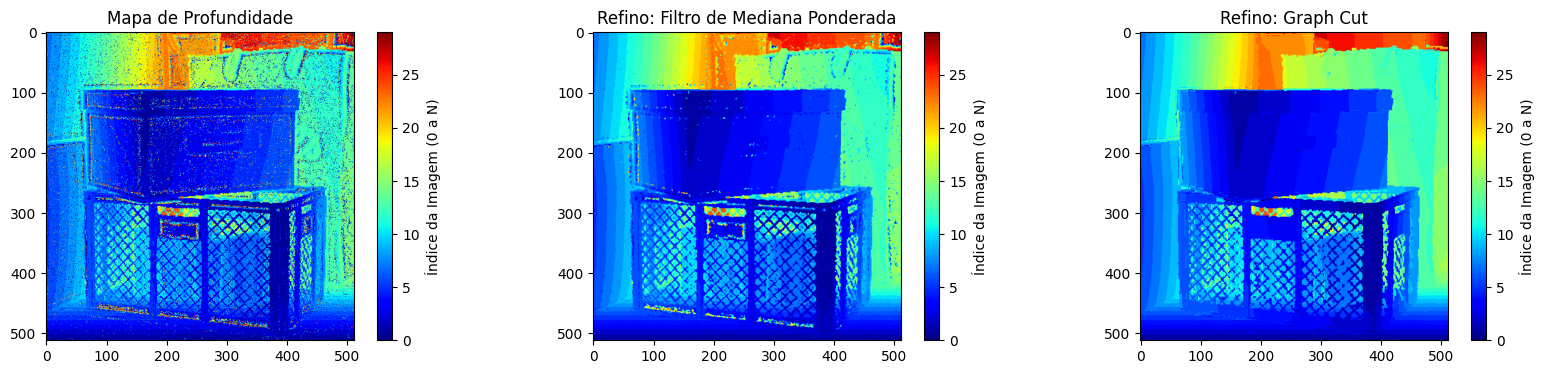

In [247]:
# Visualização do Refinamento.
fig, axs = plt.subplots(1, 3, figsize=(20, 4))

im1 = axs[0].imshow(depth, cmap='jet')
plt.colorbar(im1, ax=axs[0], label='Índice da Imagem (0 a N)')

im2 = axs[1].imshow(depth_median, cmap='jet')
fig.colorbar(im2, ax=axs[1], label='Índice da Imagem (0 a N)')

im3 = axs[2].imshow(depth_graph, cmap='jet')
plt.colorbar(im3, ax=axs[2], label='Índice da Imagem (0 a N)')

axs[0].set_title("Mapa de Profundidade")
axs[1].set_title("Refino: Filtro de Mediana Ponderada")
axs[2].set_title("Refino: Graph Cut")

plt.show()

---

### **Refinamento Completo**

Agora, vamos combinar as abordagens a fim de avaliar o resultado do  mapa de profundidades utilizando: Graph Cut e Weighted Median Filter. 

In [248]:
gray =  cv.cvtColor(img, cv.COLOR_BGR2GRAY)

initial_depth = graph_cut(volume, 10)
final_depth = wmf(initial_depth, gray)

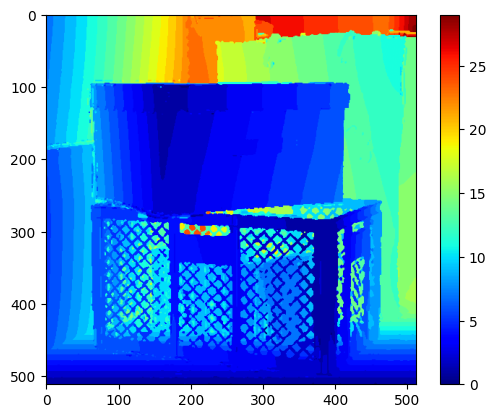

In [249]:
plt.imshow(final_depth, cmap="jet")
plt.colorbar()